In [2]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j"
    )



In [4]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j"
    )
    for record in records:
        print(record["friend.name"])



In [5]:
# Menjalankan fungsi
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


## Pertanyaan Pendahuluan (Checkpoint)
1. Apa nama database yang digunakan pada tutorial ini?   
database yang digunakan adalah neo4j. Terbukti pada parameter skrip Python, yaitu database_="neo4j"

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!  
Cara Akses Database lain dalam satu instance Neo4j dapat diakses menggunakan perintah Cypher untuk mengelola database. Contohnya:
- DDL (Data Definition Language): CREATE DATABASE nama_database; untuk membuat database, dan DROP DATABASE nama_database; untuk menghapus database.
- DML (Data Manipulation Language): CREATE, MERGE, MATCH, SET, dan DELETE untuk membuat, mencari, memperbarui, atau menghapus node dan relationship.

3. Apa jenis graf pertemanan yang telah dibuat di sini?  
Graf yang dibuat adalah graf berarah (directed graph) dengan node berlabel Person dan relationship bertipe KNOWS. dibuktikan oleh code -> pada deklarasi relasi di sintaks Cypher: (a)-[:KNOWS]->(friend)



In [6]:
# CYPHER Total Reset untuk mengosongkan database
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n;", database_="neo4j")
    print("Database berhasil dikosongkan secara total!")

Database berhasil dikosongkan secara total!


In [7]:
from neo4j import GraphDatabase
driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")


In [8]:
import os
import sys

# cek keberadaan dataset
source_folder = "data" # Mengikuti default argparse di naskah
csv_file_path = os.path.join(source_folder, "events.csv")
if not os.path.exists(csv_file_path):
    print(f"Error: File {csv_file_path} tidak ditemukan!")
# pembuatan koneksi
try:
    driver = GraphDatabase.driver(URI, auth=(AUTH))
    driver.verify_connectivity()
except Exception as e:
    print(f"Gagal terhubung ke database: {e}")

In [9]:
# Fungsi Import Cypher
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        
        UNION ALL
        
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

In [12]:
from tqdm import tqdm
from neo4j import GraphDatabase
import pandas as pd 

batch_size = 10000 

with driver.session() as session:
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE;")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE;")
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
    
    # Mengisi total baris untuk progress bar
    total_rows = 2756101 
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membaca file data dari: data\events.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [11:07<00:00,  2.42s/it]

Proses impor berhasil.


# 2.1 WRANGLING DAN EDA

### 1. Tentukan 2 periode waktu sebagai filter dari data interaksi.
 p1 = 11 Mei 2015 sampai 11 Agustus 2015 p2 = 12 Agustus 2015 sampai 06 september 2015

In [105]:
import pandas as pd
import os


df = pd.read_csv("data/events.csv")

# Konversi timestamp menjadi Datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

df_train_p1 = df[
    (df["datetime"] >= "2015-05-11") &
    (df["datetime"] < "2015-08-12")
].copy()

df_test_p2 = df[
    (df["datetime"] >= "2015-08-12") &
    (df["datetime"] < "2015-09-06")
].copy()

print("Jumlah data P1:", len(df_train_p1))
print("Jumlah data P2:", len(df_test_p2))



Jumlah data P1: 1947439
Jumlah data P2: 443350


### 2. Simpan Hasil filter timestamp ke csv 

In [106]:
df_train_p1.to_csv("data/train_P1.csv", index=False)
df_test_p2.to_csv("data/test_P2.csv", index=False)

print("Jumlah data P1:", len(df_train_p1))
print("Jumlah data P2:", len(df_test_p2))


Jumlah data P1: 1947439
Jumlah data P2: 443350


### 3. Menghitung komposisi node dengan Python API

In [60]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678") 
with driver.session() as session:
    hasil_node = session.run("""
        MATCH (n)
        UNWIND labels(n) AS label
        RETURN label, count(*) AS jumlah
        ORDER BY label
    """)

    for row in hasil_node:
        print(f"{row['label']}: {row['jumlah']} node")

Item: 235061 node
Visitor: 1407580 node


- MATCH (n): mengambil node yang ada di graf.
- labels(n): mengambil label dari setiap node.
- UNWIND ... AS label: mengubah daftar label menjadi baris-baris yang dapat dihitung.
- RETURN label, count(*) AS jumlah: menghitung jumlah kemunculan setiap label.
- ORDER BY label: mengurutkan hasil berdasarkan nama label.

### Menghitung komposisi relationship dengan Cypher

In [61]:
with driver.session() as session:
    hasil_relasi = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis, count(*) AS jumlah
        ORDER BY jenis
    """)

    for row in hasil_relasi:
        print(f"{row['jenis']}: {row['jumlah']} relationship")

ADDED_TO_CART: 69332 relationship
BOUGHT: 22457 relationship
SIMILAR_TO: 5 relationship
VIEWED: 2664312 relationship


- MATCH ()-[r]->(): mencari relationship berarah yang menghubungkan dua node.
- r: variabel yang mewakili relationship.
- type(r): mengambil jenis relationship.
- count(*) AS jumlah: menghitung jumlah relationship untuk setiap jenis.
- ORDER BY jenis: mengurutkan hasil berdasarkan jenis relationship.

### Tampilkan node realtionship

In [62]:
with driver.session() as session:
    total = session.run("""
        MATCH (n)
        WITH count(n) AS jumlah_node
        MATCH ()-[r]->()
        RETURN jumlah_node, count(r) AS jumlah_relationship
    """).single()

    print("Total node:", total["jumlah_node"])
    print("Total relationship:", total["jumlah_relationship"])

Total node: 1642641
Total relationship: 2756106


- MATCH (n): mengambil semua node.
- WITH count(n) AS jumlah_node: menghitung total node dan menyimpan hasilnya dalam variabel - jumlah_node.
- MATCH ()-[r]->(): mencari seluruh relationship.
- RETURN ... count(r): mengembalikan total node dan total relationship dalam satu hasil.
- single(): mengambil satu baris hasil.

### 4. Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User.

In [107]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from scipy.sparse import csr_matrix

df_vsm = (
    df_train_p1[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

# Ubah ID menjadi indeks angka
user_encoder = LabelEncoder()
item_encoder = LabelEncoder()

user_idx = user_encoder.fit_transform(df_vsm["visitorid"])
item_idx = item_encoder.fit_transform(df_vsm["itemid"])

n_users = len(user_encoder.classes_)
n_items = len(item_encoder.classes_)

# Buat VSM User dalam format sparse
vsm_user = csr_matrix(
    (
        [1] * len(df_vsm),
        (user_idx, item_idx)
    ),
    shape=(n_users, n_items),
    dtype="uint8"
)

In [108]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Ambil data interaksi P1
df_graph = (
    df_train_p1[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

# Bangun graf bipartit User-Item
G = nx.Graph()

users = df_graph["visitorid"].unique()
items = df_graph["itemid"].unique()

G.add_nodes_from(
    [f"U_{u}" for u in users],
    bipartite="user"
)
G.add_nodes_from(
    [f"I_{i}" for i in items],
    bipartite="item"
)

edges = [
    (f"U_{u}", f"I_{i}")
    for u, i in df_graph.itertuples(index=False, name=None)
]

G.add_edges_from(edges)

print("Network Graph User-Item")
print("Jumlah node:", G.number_of_nodes())
print("Jumlah edge:", G.number_of_edges())
print("Jumlah user:", len(users))
print("Jumlah item:", len(items))

Network Graph User-Item
Jumlah node: 1197987
Jumlah edge: 1513988
Jumlah user: 995675
Jumlah item: 202312


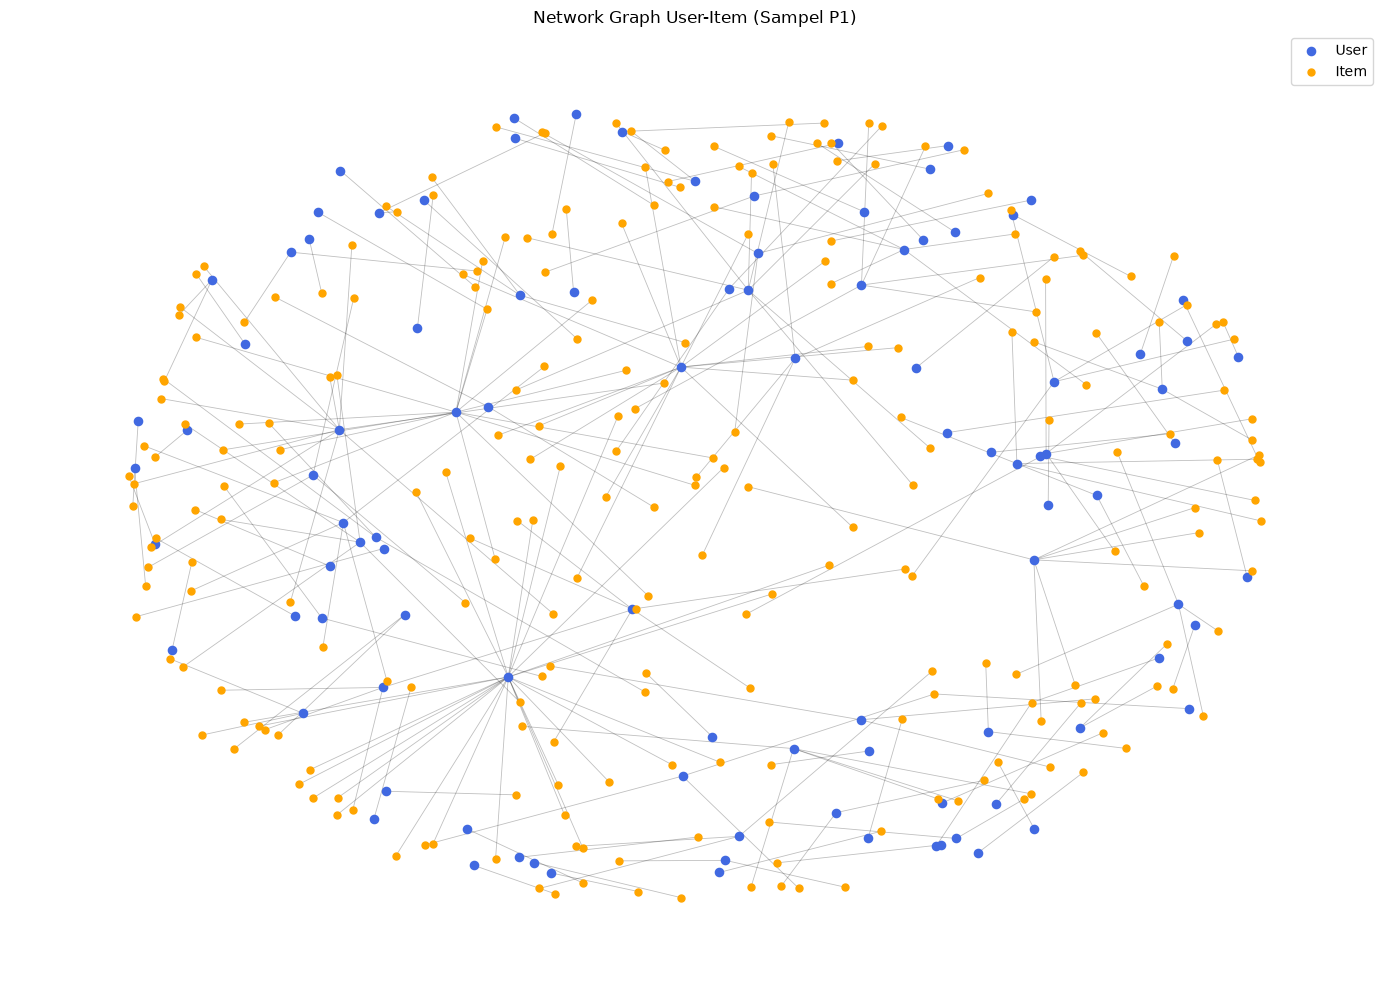

Node pada graf sampel: 343
Edge pada graf sampel: 246


In [109]:
# Ambil maksimal 100 user untuk visualisasi
max_users = 100
selected_users = set(list(users)[:max_users])

df_sample = df_graph[
    df_graph["visitorid"].isin(selected_users)
]

# Bangun graf sampel
G_sample = nx.Graph()

sample_users = df_sample["visitorid"].unique()
sample_items = df_sample["itemid"].unique()

G_sample.add_nodes_from(
    [f"U_{u}" for u in sample_users],
    node_type="User"
)
G_sample.add_nodes_from(
    [f"I_{i}" for i in sample_items],
    node_type="Item"
)

G_sample.add_edges_from([
    (f"U_{u}", f"I_{i}")
    for u, i in df_sample.itertuples(index=False, name=None)
])

# Gambar graf
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(
    G_sample,
    seed=42,
    k=0.3
)

user_nodes = [
    n for n, d in G_sample.nodes(data=True)
    if d["node_type"] == "User"
]
item_nodes = [
    n for n, d in G_sample.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_edges(
    G_sample, pos,
    alpha=0.25,
    width=0.6
)

nx.draw_networkx_nodes(
    G_sample, pos,
    nodelist=user_nodes,
    node_color="royalblue",
    node_size=35,
    label="User"
)

nx.draw_networkx_nodes(
    G_sample, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=25,
    label="Item"
)

plt.title("Network Graph User-Item (Sampel P1)")
plt.legend(scatterpoints=1)
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node pada graf sampel:", G_sample.number_of_nodes())
print("Edge pada graf sampel:", G_sample.number_of_edges())

Graf bipartit hasil sampling terdiri atas 343 node dan 246 edge. Node merepresentasikan user dan item, sedangkan edge merepresentasikan interaksi antara user dan item. Jumlah edge yang relatif lebih kecil dibandingkan jumlah node menunjukkan bahwa jaringan memiliki tingkat sparsity yang tinggi, di mana sebagian besar user hanya berinteraksi dengan sedikit item dan sebagian besar item hanya menerima interaksi dari sedikit user. Visualisasi juga memperlihatkan keberadaan beberapa node berderajat tinggi (hub) yang mengindikasikan user dengan aktivitas interaksi yang lebih tinggi dibandingkan user lainnya.

### 5. Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai Item.

In [110]:
vsm_item = vsm_user.T.tocsr()

print("VSM User (baris=user, kolom=item)")
print("Shape:", vsm_user.shape)
print("Jumlah nilai non-zero:", vsm_user.nnz)

print("\nVSM Item (baris=item, kolom=user)")
print("Shape:", vsm_item.shape)
print("Jumlah nilai non-zero:", vsm_item.nnz)

print("\nVerifikasi transpose:")
print("Shape VSM Item sama dengan transpose VSM User:",
      vsm_item.shape == vsm_user.T.shape)


VSM User (baris=user, kolom=item)
Shape: (995675, 202312)
Jumlah nilai non-zero: 1513988

VSM Item (baris=item, kolom=user)
Shape: (202312, 995675)
Jumlah nilai non-zero: 1513988

Verifikasi transpose:
Shape VSM Item sama dengan transpose VSM User: True


In [111]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Ambil pasangan User-Item dari data P1
df_graph = (
    df_train_p1[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

# Ambil sampel maksimal 100 item
max_items = 100
selected_items = df_graph["itemid"].drop_duplicates().head(max_items)

df_sample = df_graph[df_graph["itemid"].isin(selected_items)]

# Buat graph bipartit sampel
G_item = nx.Graph()

sample_users = df_sample["visitorid"].unique()
sample_items = df_sample["itemid"].unique()

G_item.add_nodes_from(
    [f"U_{u}" for u in sample_users],
    node_type="User"
)

G_item.add_nodes_from(
    [f"I_{i}" for i in sample_items],
    node_type="Item"
)

edges = [
    (f"U_{u}", f"I_{i}")
    for u, i in df_sample.itertuples(index=False, name=None)
]

G_item.add_edges_from(edges)

print("Jumlah node:", G_item.number_of_nodes())
print("Jumlah edge:", G_item.number_of_edges())
print("Jumlah User:", len(sample_users))
print("Jumlah Item:", len(sample_items))

Jumlah node: 6165
Jumlah edge: 6251
Jumlah User: 6065
Jumlah Item: 100


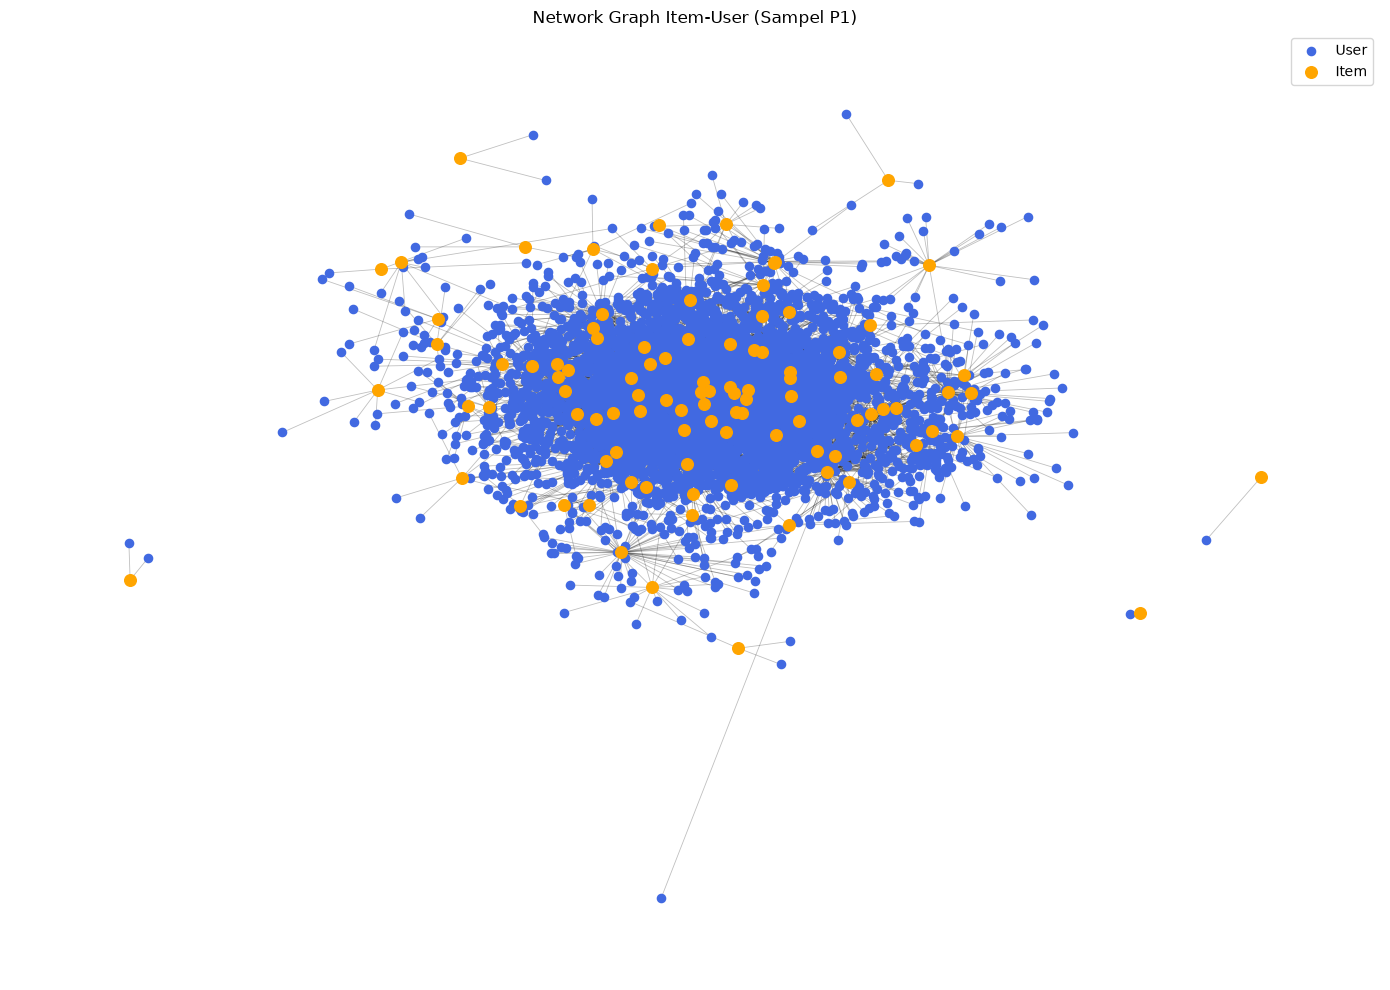

Jumlah User: 6065
Jumlah Item: 100
Node pada graf sampel: 343
Edge pada graf sampel: 246


In [112]:
plt.figure(figsize=(14, 10))

pos = nx.spring_layout(G_item, seed=42, k=0.3)

user_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "User"
]

item_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["node_type"] == "Item"
]

nx.draw_networkx_edges(
    G_item, pos,
    alpha=0.25,
    width=0.6
)

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=user_nodes,
    node_color="royalblue",
    node_size=35,
    label="User"
)

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=item_nodes,
    node_color="orange",
    node_size=70,
    label="Item"
)

plt.title("Network Graph Item-User (Sampel P1)")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah User:", len(user_nodes))
print("Jumlah Item:", len(item_nodes))
print("Node pada graf sampel:", G_sample.number_of_nodes())
print("Edge pada graf sampel:", G_sample.number_of_edges())

Visualisasi graf bipartit menunjukkan hubungan antara 6.065 user dan 100 item. Node biru menunjukkan user dan node oranye menunjukkan item. Terlihat bahwa sebagian besar user hanya memiliki sedikit interaksi, sedangkan beberapa item terhubung dengan banyak user sehingga menjadi item yang populer. Selain itu, terdapat beberapa kelompok kecil yang terpisah dari jaringan utama, yang menandakan adanya user atau item dengan interaksi yang terbatas. Secara umum, data memiliki karakteristik sparse, yaitu jumlah interaksi yang terjadi jauh lebih sedikit dibandingkan seluruh kemungkinan interaksi antara user dan item.

### 6. Berdasarkan hasil eksplorasi dimensi matriks pada nomor 4 dan 5, 
proyeksi yang lebih baik, efektif, dan efisien secara komputasi untuk dataset ini adalah Proyeksi **VSM User**.  
Alasan Analisis:
proyeksi User dipilih untuk analisis rekomendasi berbasis kemiripan antar-user karena sesuai dengan tujuan analisis. Namun, dari sisi efisiensi komputasi, belum dapat disimpulkan bahwa proyeksi User lebih unggul hanya berdasarkan dimensi matriks dan visualisasi sampel. Kedua matriks memiliki jumlah elemen yang sama karena saling transpose, sedangkan graf sampel dengan 343 node dan 246 edge hanya menggambarkan sebagian hubungan User–Item. Untuk memastikan proyeksi yang paling efisien, diperlukan perbandingan waktu komputasi dan penggunaan memori pada kedua proyeksi.

### 7. Perhitungan Cosine Similarity menggunakan Python

In [81]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors

# Pastikan VSM User sudah dibuat
print("Dimensi VSM User:", vsm_user.shape)

# Pilih satu target user secara konsisten:
# user dengan jumlah interaksi terbanyak
jumlah_interaksi = np.asarray(vsm_user.sum(axis=1)).ravel()
target_idx = int(np.argmax(jumlah_interaksi))

# Ambil ID user asli
target_user_id = user_encoder.inverse_transform([target_idx])[0]

# Model pencarian user terdekat berdasarkan cosine distance
k = min(6, vsm_user.shape[0])

model_knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=k,
    n_jobs=-1
)

model_knn.fit(vsm_user)

# Cari user yang paling mirip dengan target
distances, indices = model_knn.kneighbors(
    vsm_user[target_idx],
    n_neighbors=k
)

# Ubah cosine distance menjadi cosine similarity
similarities = 1 - distances.ravel()

# Susun hasil, kecuali target user itu sendiri
hasil_similarity = []

for idx, similarity in zip(indices.ravel(), similarities):
    if idx != target_idx:
        user_id = user_encoder.inverse_transform([idx])[0]

        hasil_similarity.append({
            "target_user": target_user_id,
            "similar_user": user_id,
            "cosine_similarity": float(similarity)
        })

df_similarity = pd.DataFrame(hasil_similarity)
df_similarity = df_similarity.sort_values(
    "cosine_similarity",
    ascending=False
).head(5).reset_index(drop=True)

print("Target User:", target_user_id)
print("\nTop 5 User Paling Mirip:")
display(df_similarity)

Dimensi VSM User: (995675, 202312)
Target User: 1150086

Top 5 User Paling Mirip:


,target_user,similar_user,cosine_similarity
0,1150086,530559,0.226375
1,1150086,371606,0.198173
2,1150086,1297062,0.190162
3,1150086,684514,0.170833
4,1150086,705542,0.167618


### 7a) Penjelasan CYPHER QUERY:

Pada bagian ini, dilakukan perhitungan cosine similarity antar-Visitor menggunakan query Cypher pada Neo4j. Visitor acuan yang digunakan adalah Visitor dengan `visitorId = 123`. 

Perhitungan dilakukan dengan mencari Item yang sama-sama terhubung dengan Visitor acuan dan Visitor lainnya. Jumlah Item unik milik setiap Visitor digunakan untuk menghitung nilai cosine similarity 
Nilai similarity kemudian diurutkan secara menurun menggunakan ORDER BY CosineSimilarity DESC, lalu diambil lima record teratas menggunakan `LIMIT 5`. Hasil query menampilkan ID Visitor acuan, ID Visitor yang paling mirip, dan nilai cosine similarity masing-masing.

In [84]:
query_7a = """
MATCH (u1:Visitor {visitorId: 123})-[]->(i:Item)
WITH u1, count(DISTINCT i) AS degree1

MATCH (u1)-[]->(shared:Item)<-[]-(u2:Visitor)
WHERE u1 <> u2

WITH u1, degree1, u2, count(DISTINCT shared) AS intersection

MATCH (u2)-[]->(i2:Item)
WITH u1, degree1, u2, intersection,
     count(DISTINCT i2) AS degree2

WITH u1, u2,
     toFloat(intersection) /
     (sqrt(degree1) * sqrt(degree2)) AS similarity

RETURN
    u1.visitorId AS TargetVisitor,
    u2.visitorId AS SimilarVisitor,
    similarity AS CosineSimilarity
ORDER BY CosineSimilarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records_7a, _, _ = driver.execute_query(
        query_7a,
        database_="neo4j"
    )

data_7a = [
    {
        "Target Visitor": r["TargetVisitor"],
        "Similar Visitor": r["SimilarVisitor"],
        "Cosine Similarity": round(r["CosineSimilarity"], 4)
    }
    for r in records_7a
]

display(pd.DataFrame(data_7a))

,Target Visitor,Similar Visitor,Cosine Similarity
0,123,1141751,1.0
1,123,1200957,1.0
2,123,81096,1.0
3,123,686433,1.0
4,123,1128395,1.0


### 7(b) Penulisan Nilai Similarity pada Graf

Pada bagian ini, lima hasil cosine similarity dari perhitungan sebelumnya disimpan sebagai relasi SIMILAR_TO pada graf Neo4j. Relasi dibuat dari Visitor acuan menuju Visitor yang memiliki kemiripan tertinggi menggunakan perintah MERGE.

Nilai cosine similarity disimpan pada properti score melalui perintah SET sim.score = similarity. Penggunaan MERGE membantu menghindari pembuatan relasi baru yang sama pada setiap eksekusi, selama pasangan node dan arah relasinya sama.

Query kemudian mengembalikan ID Visitor acuan, ID Visitor yang mirip, dan nilai similarity yang telah disimpan. Untuk memvisualisasikan hasilnya, node Visitor dan relasi SIMILAR_TO ditampilkan melalui Neo4j Browser sehingga hubungan serta nilai similarity dapat diperiksa pada graf..

In [85]:
query_7b = """
MATCH (u1:Visitor {visitorId: 123})-[]->(i:Item)
WITH u1, count(DISTINCT i) AS degree1

MATCH (u1)-[]->(shared:Item)<-[]-(u2:Visitor)
WHERE u1 <> u2

WITH u1, degree1, u2, count(DISTINCT shared) AS intersection

MATCH (u2)-[]->(i2:Item)
WITH u1, degree1, u2, intersection,
     count(DISTINCT i2) AS degree2

WITH u1, u2,
     toFloat(intersection) /
     (sqrt(degree1) * sqrt(degree2)) AS similarity

ORDER BY similarity DESC
LIMIT 5

MERGE (u1)-[sim:SIMILAR_TO]->(u2)
SET sim.score = similarity

RETURN
    u1.visitorId AS TargetVisitor,
    u2.visitorId AS SimilarVisitor,
    sim.score AS SkorTersimpan
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records_7b, _, _ = driver.execute_query(
        query_7b,
        database_="neo4j"
    )

data_7b = [
    {
        "Target Visitor": r["TargetVisitor"],
        "Similar Visitor": r["SimilarVisitor"],
        "Skor Tersimpan di Graf": round(r["SkorTersimpan"], 4)
    }
    for r in records_7b
]

display(pd.DataFrame(data_7b))

,Target Visitor,Similar Visitor,Skor Tersimpan di Graf
0,123,1141751,1.0
1,123,1200957,1.0
2,123,81096,1.0
3,123,686433,1.0
4,123,1128395,1.0


### 8. Kondisi graf sebelum dan sesudah perhitungan similarity

- **Sebelum similarity:** graf berisi relasi interaksi asli antara Visitor dan Item (VIEWED, ADDED_TO_CART, atau BOUGHT). Belum ada relasi SIMILAR_TO yang dibuat oleh proses similarity ini.  
cypher  
MATCH (v:Visitor)-[r]->(i:Item)  
RETURN v, r, i  
LIMIT 100


- **Sesudah similarity:** setelah query 7(b) dijalankan, graf menyimpan relasi SIMILAR_TO dari visitor target ke lima visitor paling mirip, beserta properti score.
cypher  
MATCH (v:Visitor {visitorId: 123})-[r:SIMILAR_TO]->(u:Visitor)  
RETURN v, r, u  
ORDER BY r.score DESC  
LIMIT 5


### Visualisasi graf  sebelum dan sesudah perhitungan similarity!

Jumlah relasi yang ditemukan: 100


,visitor_id,relasi,item_id
0,409242,VIEWED,5893
1,409242,VIEWED,5893
2,1029261,VIEWED,5893
3,1280004,VIEWED,5893
4,862523,VIEWED,5893
5,191754,VIEWED,5893
6,573702,VIEWED,5893
7,920498,VIEWED,5893
8,43841,VIEWED,5893
9,43841,VIEWED,5893


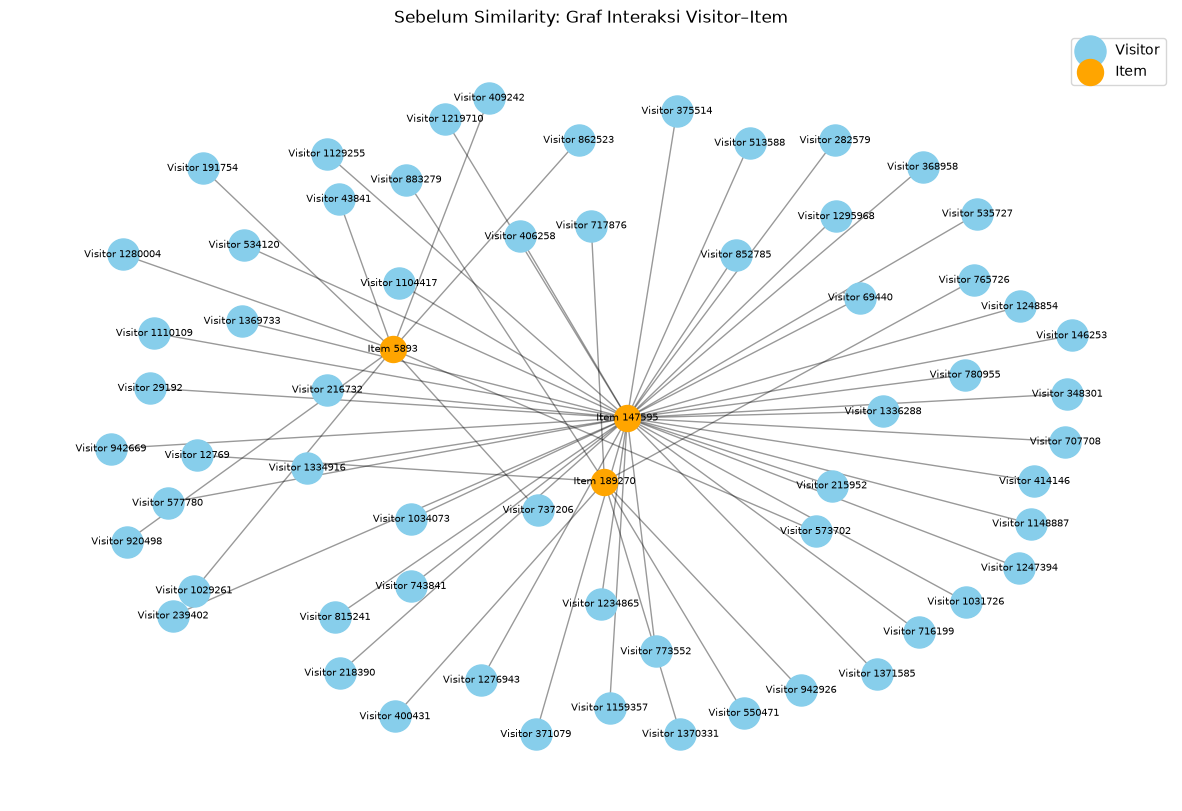

In [113]:

query_before = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor_id,
       type(r) AS relasi,
       i.itemId AS item_id
LIMIT 100
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        query_before,
        database_="neo4j"
    )

df_before = pd.DataFrame([r.data() for r in records])

print("Jumlah relasi yang ditemukan:", len(df_before))
display(df_before.head(10))

if not df_before.empty:
    G_before = nx.Graph()

    for _, row in df_before.iterrows():
        visitor = f"Visitor {row['visitor_id']}"
        item = f"Item {row['item_id']}"
        G_before.add_node(visitor, jenis="Visitor")
        G_before.add_node(item, jenis="Item")
        G_before.add_edge(visitor, item, relasi=row["relasi"])

    plt.figure(figsize=(15, 10))
    pos = nx.spring_layout(G_before, seed=42, k=0.8)

    visitor_nodes = [
        n for n, d in G_before.nodes(data=True)
        if d["jenis"] == "Visitor"
    ]
    item_nodes = [
        n for n, d in G_before.nodes(data=True)
        if d["jenis"] == "Item"
    ]

    nx.draw_networkx_nodes(
        G_before, pos, nodelist=visitor_nodes,
        node_color="skyblue", node_size=500,
        label="Visitor"
    )
    nx.draw_networkx_nodes(
        G_before, pos, nodelist=item_nodes,
        node_color="orange", node_size=350,
        label="Item"
    )
    nx.draw_networkx_edges(G_before, pos, alpha=0.4)
    nx.draw_networkx_labels(G_before, pos, font_size=7)

    plt.title("Sebelum Similarity: Graf Interaksi Visitor–Item")
    plt.legend()
    plt.axis("off")
    plt.show()
else:
    print("Tidak ada relasi Visitor–Item yang ditemukan.")


,target_visitor,similar_visitor,similarity
0,123,1200957,1.0
1,123,81096,1.0
2,123,686433,1.0
3,123,1141751,1.0
4,123,1128395,1.0


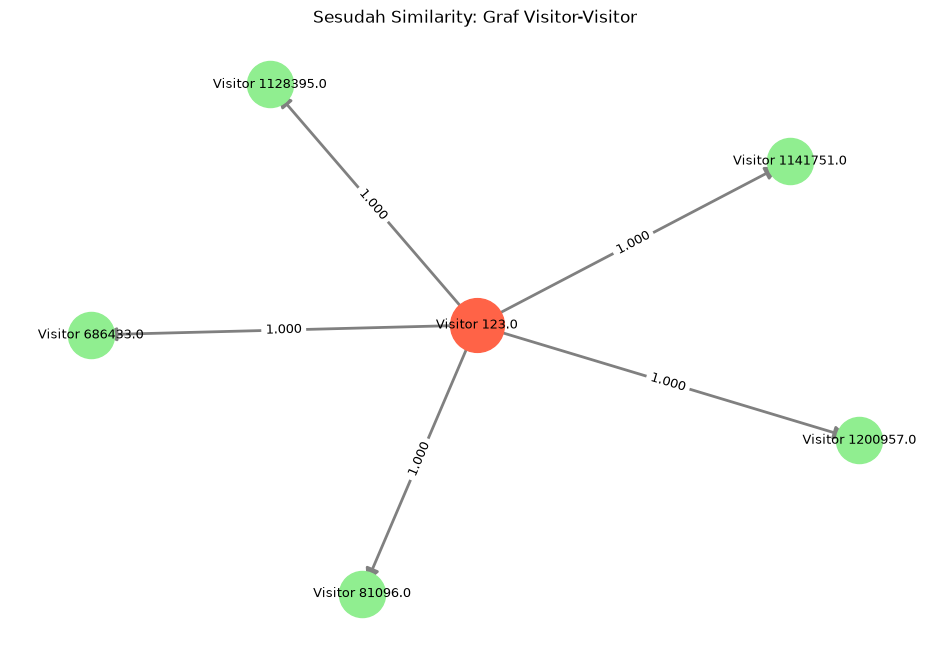

In [114]:

query_after = """
MATCH (v:Visitor {visitorId: 123})-[r:SIMILAR_TO]->(u:Visitor)
RETURN v.visitorId AS target_visitor,
       u.visitorId AS similar_visitor,
       r.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        query_after,
        database_="neo4j"
    )

df_after = pd.DataFrame([record.data() for record in records])
display(df_after)

# Bentuk graf similarity
G_after = nx.DiGraph()

for _, row in df_after.iterrows():
    target = f"Visitor {row['target_visitor']}"
    similar = f"Visitor {row['similar_visitor']}"
    score = float(row["similarity"])

    G_after.add_node(target, jenis="Target")
    G_after.add_node(similar, jenis="Similar")
    G_after.add_edge(target, similar, weight=score)

# Visualisasi
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_after, seed=42)

target_nodes = [
    n for n, d in G_after.nodes(data=True)
    if d["jenis"] == "Target"
]
similar_nodes = [
    n for n, d in G_after.nodes(data=True)
    if d["jenis"] == "Similar"
]

nx.draw_networkx_nodes(
    G_after, pos, nodelist=target_nodes,
    node_color="tomato", node_size=1500
)
nx.draw_networkx_nodes(
    G_after, pos, nodelist=similar_nodes,
    node_color="lightgreen", node_size=1100
)
nx.draw_networkx_edges(
    G_after, pos, arrows=True, arrowsize=20,
    width=2, edge_color="gray"
)
nx.draw_networkx_labels(G_after, pos, font_size=9)

edge_labels = {
    (u, v): f"{d['weight']:.3f}"
    for u, v, d in G_after.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G_after, pos, edge_labels=edge_labels,
    font_size=9
)

plt.title("Sesudah Similarity: Graf Visitor-Visitor")
plt.axis("off")
plt.show()


### Penjelasan visualisasi graf
- Sebelum similarity Graf Visitor Item graf **belum menunjukkan tingkat kemiripan antar-Visitor**. Graf hanya memperlihatkan hubungan interaksi Visitor–Item yang menjadi dasar perhitungan similarity.

- Sesudah similarity Graf Visitor Visitor ada visualisasi sesudah similarity, terlihat Visitor 123 terhubung dengan lima Visitor lain, yaitu Visitor 1128395, Visitor 1141751, Visitor 1200957, Visitor 81096, dan Visitor 686433.
Setiap hubungan memiliki skor cosine similarity sebesar 1.000. Berdasarkan hasil pemeriksaan sebelumnya, item bersama yang dimiliki oleh pasangan Visitor tersebut memang identik. Oleh karena itu, skor cosine similarity sebesar 1 menunjukkan bahwa pola item kedua Visitor sama pada representasi data yang digunakan.

- kesimpulan Berdasarkan hasil visualisasi, graf sebelum similarity menggambarkan hubungan interaksi antara Visitor dan Item yang menjadi dasar analisis. Selanjutnya, proses cosine similarity digunakan untuk mengidentifikasi Visitor yang memiliki pola item serupa dengan Visitor target.
Pada hasil sesudah similarity, lima Visitor memiliki skor cosine similarity sebesar 1.000. Nilai ini konsisten dengan hasil pemeriksaan bahwa item yang dimiliki bersama identik pada pasangan yang dianalisis. Dengan demikian, proses similarity berhasil menunjukkan hubungan kemiripan antar-Visitor berdasarkan pola item.
Hasil similarity tersebut dapat menjadi dasar untuk tahap rekomendasi berikutnya, misalnya dengan melihat item yang dimiliki Visitor serupa tetapi belum pernah diinteraksikan oleh Visitor target.


# 2.2 Analytics

### 1 a) skrip Python Untuk merekomendasikan KNN

In [116]:
import numpy as np
import pandas as pd

# Pilih user secara acak dan reproducible dari user yang:
# (1) muncul di VSM P1, dan (2) memiliki interaksi pada periode P2.
# Dengan begitu, Hit@5 dan NDCG@5 memiliki ground truth untuk dievaluasi.
users_p2 = set(df_test_p2["visitorid"].dropna().unique())
eligible_user_ids = np.array([
    uid for uid in user_encoder.classes_
    if uid in users_p2
])

if len(eligible_user_ids) == 0:
    raise ValueError(
        "Tidak ada user yang muncul pada P1 dan P2. "
        "Periksa kembali batas periode atau dataset."
    )

random_state = 42
rng = np.random.default_rng(random_state)
target_user = rng.choice(eligible_user_ids)
target_idx = int(user_encoder.transform([target_user])[0])

print("Random state:", random_state)
print("User target yang dipilih:", target_user)
print("Jumlah user yang memenuhi syarat evaluasi:", len(eligible_user_ids))
print("Jumlah item yang diakses user di P2:",
      df_test_p2.loc[df_test_p2["visitorid"] == target_user, "itemid"].nunique())


Random state: 42
User target yang dipilih: 124004
Jumlah user yang memenuhi syarat evaluasi: 19836
Jumlah item yang diakses user di P2: 1


In [117]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

# Gunakan target_user dan target_idx yang sudah dipilih pada sel sebelumnya.
k = 5
if vsm_user.shape[0] < 2:
    raise ValueError("Jumlah User harus minimal 2 untuk KNN.")

n_neighbors = min(k + 1, vsm_user.shape[0])
knn = NearestNeighbors(
    n_neighbors=n_neighbors,
    metric="cosine",
    algorithm="brute"
)
knn.fit(vsm_user)

distances, indices = knn.kneighbors(
    vsm_user[target_idx],
    n_neighbors=n_neighbors
)

neighbors = []
for distance, idx in zip(distances[0], indices[0]):
    if idx == target_idx:
        continue
    neighbors.append({
        "Visitor ID": user_encoder.inverse_transform([idx])[0],
        "Cosine Similarity": max(0.0, 1 - float(distance))
    })
    if len(neighbors) == k:
        break

df_knn = pd.DataFrame(neighbors)
print("User target:", target_user)
print("Lima tetangga terdekat (k=5):")
display(df_knn.round({"Cosine Similarity": 4}))


User target: 124004
Lima tetangga terdekat (k=5):


,Visitor ID,Cosine Similarity
0,5005,0.4082
1,7441,0.4082
2,7112,0.4082
3,1387024,0.4082
4,1278111,0.4082


### 1a. Pilih seorang user secara acak

User dipilih secara acak menggunakan np.random.default_rng(42) dari user yang muncul pada periode training P1 dan memiliki setidaknya satu interaksi pada periode testing P2. Pembatasan ini membuat evaluasi Hit@5 dan NDCG@5 dapat dibandingkan dengan ground truth P2. Seed 42 membuat pemilihan dapat direproduksi selama data dan urutan ID tidak berubah.

KNN menggunakan k = 5 dan metrik cosine distance. User target sendiri dikeluarkan dari daftar tetangga, sehingga tabel menampilkan maksimal lima user lain dengan kemiripan tertinggi.


### 1 b) 3 item yang diiklankan untuk k = 5

In [118]:
import numpy as np
import pandas as pd
from collections import defaultdict

# Rekomendasi User-Based Collaborative Filtering untuk k=5
k = 5
n_search = min(k + 1, vsm_user.shape[0])
distances, indices = knn.kneighbors(
    vsm_user[target_idx],
    n_neighbors=n_search
)

neighbors = []
for distance, idx in zip(distances[0], indices[0]):
    if idx == target_idx:
        continue
    neighbors.append((idx, max(0.0, 1.0 - float(distance))))
    if len(neighbors) == k:
        break

print("User target:", target_user)
print("Jumlah tetangga yang digunakan:", len(neighbors))

# Kumpulkan item dari tetangga yang belum pernah diakses target.
skor_item = defaultdict(float)
for neighbor_idx, similarity in neighbors:
    for item_idx in vsm_user[neighbor_idx].indices:
        if vsm_user[target_idx, item_idx] == 0:
            skor_item[item_idx] += similarity

# Jika semua similarity bernilai nol/tidak ada kandidat dari tetangga,
# gunakan popularitas item P1 sebagai fallback, tetap mengecualikan item
# yang sudah pernah diakses user target.
if not skor_item:
    popularitas = np.asarray(vsm_user.sum(axis=0)).ravel()
    for item_idx in np.argsort(popularitas)[::-1]:
        if popularitas[item_idx] > 0 and vsm_user[target_idx, item_idx] == 0:
            skor_item[int(item_idx)] = float(popularitas[item_idx])

# Soal meminta 3 item yang diiklankan untuk k=5.
top_n = 3
rekomendasi = sorted(
    skor_item.items(),
    key=lambda x: x[1],
    reverse=True
)[:top_n]

df_rekomendasi = pd.DataFrame([
    {
        "Ranking": rank,
        "Item ID": item_encoder.inverse_transform([item_idx])[0],
        "Skor Rekomendasi": round(score, 4)
    }
    for rank, (item_idx, score) in enumerate(rekomendasi, start=1)
])

if df_rekomendasi.empty:
    print("Tidak ada item baru yang dapat direkomendasikan.")
else:
    print("Tiga item rekomendasi untuk k=5:")
    display(df_rekomendasi)


User target: 124004
Jumlah tetangga yang digunakan: 5
Tiga item rekomendasi untuk k=5:


,Ranking,Item ID,Skor Rekomendasi
0,1,5411,1805.0
1,2,370653,1189.0
2,3,298009,1055.0


### 1(b). Analisis hasil rekomendasi

Sistem menggunakan *User-Based Collaborative Filtering* dengan KNN (k = 5). Kandidat rekomendasi berasal dari item yang diakses oleh lima tetangga terdekat tetapi belum pernah diakses oleh user target. Skor item dihitung dari penjumlahan cosine similarity tetangga yang terkait.

Sesuai instruksi soal, hasil yang ditampilkan adalah tiga item rekomendasi. Jika tidak ada kandidat dari tetangga (misalnya semua similarity nol atau tidak ada item baru), sistem menggunakan item populer pada P1 sebagai fallback sambil tetap mengecualikan item yang telah diakses user target. Skor fallback merepresentasikan popularitas, bukan skor kemiripan personal.


### 2 a) Hit@5 (Hit Rate at 5)
Hit@5 adalah metrik biner yang mengevaluasi apakah model berhasil merekomendasikan setidaknya satu item yang benar.  
- Jika dari 5 rekomendasi terdapat minimal 1 item yang benar-benar ada di riwayat aktual data Testing (Ground Truth), maka nilainya 1.   
- Jika kelima tebakan model meleset sama sekali, maka nilainya 0.

In [119]:
# 2(a) Evaluasi Hit@5

item_relevan = set(
    df_test_p2.loc[
        df_test_p2["visitorid"] == target_user, "itemid"
    ].dropna().unique()
)

top_5_rekomendasi = (
    df_rekomendasi["Item ID"].head(5).tolist()
    if not df_rekomendasi.empty
    else []
)

if len(item_relevan) == 0:
    hit_at_5 = np.nan
    print("Hit@5: tidak dapat dievaluasi (tidak ada item relevan di P2)")
else:
    hit_at_5 = int(any(item in item_relevan for item in top_5_rekomendasi))
    print("User target:", target_user)
    print("Jumlah item relevan pada P2:", len(item_relevan))
    print("Jumlah rekomendasi yang tersedia:", len(top_5_rekomendasi))
    print("Hit@5:", hit_at_5)


User target: 124004
Jumlah item relevan pada P2: 1
Jumlah rekomendasi yang tersedia: 3
Hit@5: 0


Hit@5 bernilai 1 jika setidaknya satu item pada daftar rekomendasi (maksimal lima item) muncul pada interaksi aktual user di P2; jika tidak ada yang cocok, nilainya 0. Jika user tidak memiliki interaksi/item relevan pada P2, metrik ditandai tidak dapat dievaluasi, bukan dianggap gagal. Karena soal meminta tiga item rekomendasi, evaluasi menggunakan seluruh item yang tersedia hingga batas Top-5.
pada percobaan ini Hit@5 bernilai 0 berarti **user 124004 tidak memiliki interaksi/item relevan pada P2**


### 2 b) NDCG@5 (Normalized Discounted Cumulative Gain)
 NDCG@5 mengevaluasi kualitas urutan (ranking). Sebuah tebakan yang benar akan diberi skor (bobot) yang jauh lebih tinggi jika berada di urutan pertama dibandingkan jika berada di urutan kelima menggunakan perhitungan logaritmik (DCG).   
 Nilai akhirnya dinormalisasi (dibagi dengan IDCG / kondisi paling ideal) sehingga skor selalu berada di rentang 0.0 hingga 1.0.

In [120]:
import numpy as np

# Ground truth relevansi untuk user target pada P2
item_relevan = set(
    df_test_p2.loc[
        df_test_p2["visitorid"] == target_user, "itemid"
    ].dropna().unique()
)

top_5_rekomendasi = (
    df_rekomendasi["Item ID"].head(5).tolist()
    if not df_rekomendasi.empty
    else []
)

if len(item_relevan) == 0:
    ndcg_at_5 = np.nan
    print("NDCG@5: tidak dapat dievaluasi (tidak ada item relevan di P2)")
else:
    # Relevansi biner pada posisi rekomendasi; posisi yang tidak terisi
    # dianggap relevansi 0.
    relevansi = [int(item in item_relevan) for item in top_5_rekomendasi]
    relevansi += [0] * (5 - len(relevansi))

    # Ideal ranking: letakkan item relevan sebanyak mungkin pada posisi awal.
    relevansi_ideal = [1] * min(len(item_relevan), 5) + [0] * (5 - min(len(item_relevan), 5))

    dcg = sum(rel / np.log2(pos + 2) for pos, rel in enumerate(relevansi))
    idcg = sum(rel / np.log2(pos + 2) for pos, rel in enumerate(relevansi_ideal))
    ndcg_at_5 = dcg / idcg if idcg > 0 else np.nan

    print("User target:", target_user)
    print("Jumlah item relevan pada P2:", len(item_relevan))
    print("Jumlah rekomendasi yang tersedia:", len(top_5_rekomendasi))
    print("NDCG@5:", round(float(ndcg_at_5), 4))


User target: 124004
Jumlah item relevan pada P2: 1
Jumlah rekomendasi yang tersedia: 3
NDCG@5: 0.0


**Analisis NDCG@5**

NDCG@5 mengevaluasi apakah item relevan muncul pada posisi ranking yang lebih tinggi. Skor berada pada rentang 0 sampai 1 ketika terdapat setidaknya satu item relevan di P2. Skor 1 berarti semua item relevan yang ditemukan pada batas Top-5 berada dalam urutan ideal; skor lebih rendah menunjukkan urutan yang kurang ideal.

Jika tidak ada item relevan di P2, NDCG@5 ditandai tidak dapat dievaluasi karena IDCG bernilai nol. Karena itu, user target dipilih dari user yang memiliki interaksi di P1 dan P2 agar evaluasi memiliki ground truth. Hasil angka akhir harus diambil dari output setelah seluruh sel dijalankan ulang.

**Model rekomendasi belum berhasil menemukan item relevan untuk user 124004. Meskipun sistem menghasilkan tiga rekomendasi, ketiganya tidak sesuai dengan satu item relevan pada data P2.**
